# Практическая работа 2. Двумерные массивы и изображения
## Самостоятельные и контрольные задания

Параметры всех заданий берутся из паспортов A–G (файл `lab02_2d_arrays_images_variants_v1`) по номеру варианта `VARIANT`. Чтобы получить решение для другого варианта, поменяйте номер в ячейке ниже и выполните блокнот заново (*Run All*).

In [19]:
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

VARIANT = 1   # <--- номер вашего варианта (1..25)

In [20]:
# ВРУЧНУЮ ПРОПИСАННЫЕ ПАСПОРТА ДЛЯ ВАРИАНТА 1

# Паспорт A. Двумерный массив
A = {'n_rows': 4, 'n_cols': 6, 'a': 10, 'b': -1}

# Паспорт B. Изображение
B = {'H': 180, 'W': 280, 'bg': 0}

# Паспорт C. Точка
Cp = {'x': 57, 'y': 49, 'g': 120}

# Паспорт D. Отрезок
D = {'x1': 23, 'y1': 21, 'x2': 248, 'y2': 146, 'g': 140, 'thickness': 2}

# Паспорт E. Прямоугольник
E = {'x1': 24, 'y1': 22, 'x2': 89, 'y2': 72, 'g': 130, 'thickness': -1}

# Паспорт F. Окружность
F = {'x0': 122, 'y0': 90, 'R': 21, 'g': 150, 'thickness': -1}

# Паспорт G. Цвет OpenCV (B, G, R)
G = {'B': 0, 'G': 0, 'R': 255}

> Примечание: в методичке для быстрого просмотра используется `Image.fromarray(img).show()` (внешнее окно). В блокноте с готовыми результатами используется `plt.imshow`; строка `Image.fromarray(img).show()` работает так же и может быть добавлена в любую ячейку.

# Самостоятельные задания

## С1. Двумерный массив по формуле
Паспорт A: $m_{r,c}=ar+c+b$.

In [ ]:
n_rows, n_cols = A["n_rows"], A["n_cols"]
m = np.zeros((n_rows, n_cols), dtype=int)

for r in range(n_rows):
    for c in range(n_cols):
        m[r, c] = A["a"] * r + c + A["b"]

print(m)
n_rows_m, n_cols_m = m.shape
print("shape =", m.shape)
print("n_rows =", n_rows_m)
print("n_cols =", n_cols_m)
print("m[0, 0] =", m[0, 0])
print("m[1, 2] =", m[1, 2])
print("m[3, 5] =", m[3, 5])

[[-1  0  1  2  3  4]
 [ 9 10 11 12 13 14]
 [19 20 21 22 23 24]
 [29 30 31 32 33 34]]
shape = (4, 6)
n_rows = 4
n_cols = 6
m[0, 0] = -1
m[1, 2] = 11
m[3, 5] = 34


## С2. Полутоновый холст и пиксель
Паспорта B и C. Пиксель $(x,y)$ записывается как `img[y, x]`.

shape = (180, 280)
dtype = uint8
img[y, x] = 120


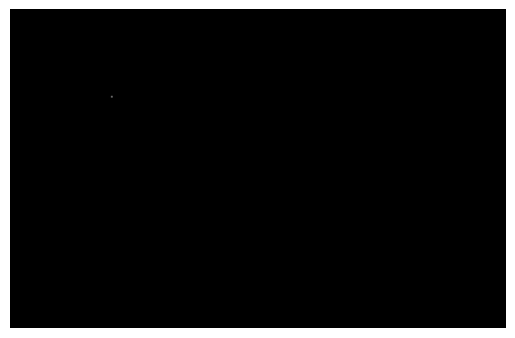

In [38]:
H, W = B["H"], B["W"]
img = np.zeros((H, W), dtype=np.uint8)

x, y = Cp["x"], Cp["y"]
img[y, x] = Cp["g"]

print("shape =", img.shape)
print("dtype =", img.dtype)
print("img[y, x] =", img[y, x])

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

## С3. Прямоугольная область
Паспорта B и E: залитый прямоугольник (a) срезом NumPy, (б) `cv2.rectangle(..., -1)`.

Максимальная разность = 0
Число различающихся пикселей = 0


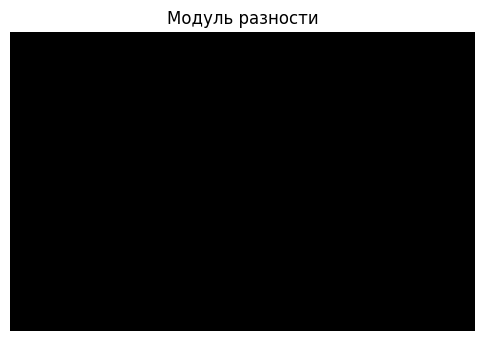

In [39]:
H, W = B["H"], B["W"]

x1, y1 = E["x1"], E["y1"]
x2, y2 = E["x2"], E["y2"]

img_slice = np.zeros((H, W), dtype=np.uint8)
img_slice[y1:y2 + 1, x1:x2 + 1] = E["g"]

img_cv = np.zeros((H, W), dtype=np.uint8)
cv2.rectangle(img_cv, (x1, y1), (x2, y2), E["g"], -1)

diff = cv2.absdiff(img_slice, img_cv)

print("Максимальная разность =", diff.max())
print("Число различающихся пикселей =", np.count_nonzero(diff))

Image.fromarray(img_slice).show()
Image.fromarray(img_cv).show()
Image.fromarray(diff).show()

plt.figure(figsize=(6, 4))
plt.imshow(diff, cmap="gray", vmin=0, vmax=255)
plt.title("Модуль разности")
plt.axis("off")
plt.show()

## С4. Отрезок и окружность
Паспорта B, D и F на одном изображении.

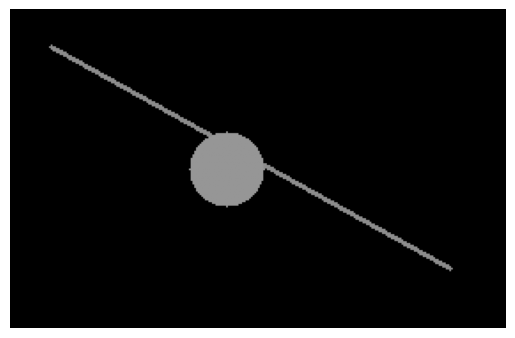

In [40]:
H, W = B["H"], B["W"]
img = np.zeros((H, W), dtype=np.uint8)

cv2.line(
    img,
    (D["x1"], D["y1"]),
    (D["x2"], D["y2"]),
    D["g"],
    D["thickness"],
)

cv2.circle(
    img,
    (F["x0"], F["y0"]),
    F["R"],
    F["g"],
    F["thickness"],
)

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

## С5. Составное изображение
Паспорта B, C, D, E, F: точка, отрезок, прямоугольник, окружность.

**Связь координат и индексов:** $x=c$ (столбец), $y=r$ (строка), поэтому точка $(x,y)$ — это `img[y, x]`. Функции OpenCV (`line`, `rectangle`, `circle`) принимают точки в порядке `(x, y)`.

Точка (x, y) = (57, 49) -> img[y, x] = img[ 49 , 57 ]


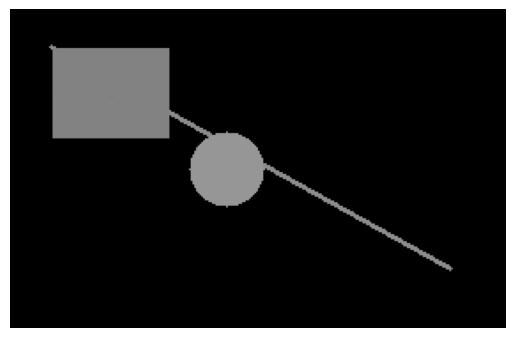

In [41]:
H, W = B["H"], B["W"]
img = np.zeros((H, W), dtype=np.uint8)

cv2.line(img, (D["x1"], D["y1"]), (D["x2"], D["y2"]), D["g"], D["thickness"])
cv2.rectangle(img, (E["x1"], E["y1"]), (E["x2"], E["y2"]), E["g"], E["thickness"])
cv2.circle(img, (F["x0"], F["y0"]), F["R"], F["g"], F["thickness"])

img[Cp["y"], Cp["x"]] = Cp["g"]

print("Точка (x, y) =", (Cp["x"], Cp["y"]), "-> img[y, x] = img[", Cp["y"], ",", Cp["x"], "]")

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

## С6. Цвет OpenCV и PIL
Паспорта B, E, G: цветной прямоугольник; цвет в OpenCV задан как $(B,G,R)$, для PIL/Matplotlib нужно преобразование в RGB.

shape = (180, 280, 3)


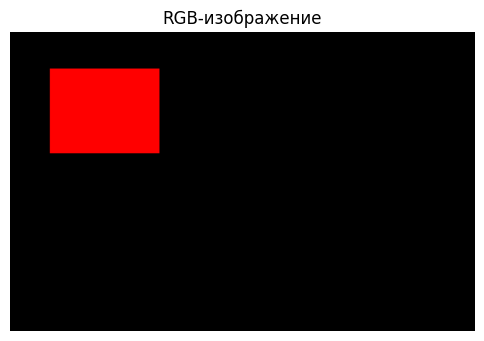

In [42]:
H, W = B["H"], B["W"]
img_bgr = np.zeros((H, W, 3), dtype=np.uint8)

cv2.rectangle(
    img_bgr,
    (E["x1"], E["y1"]),
    (E["x2"], E["y2"]),
    (G["B"], G["G"], G["R"]),
    E["thickness"],
)

print("shape =", img_bgr.shape)

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

Image.fromarray(img_rgb).show()

plt.figure(figsize=(6, 4))
plt.imshow(img_rgb)
plt.title("RGB-изображение")
plt.axis("off")
plt.show()

In [48]:
m1 = np.zeros(10, dtype=int)

m1[3:7] = 2

print("Массив 1D после среза [3:7]:")
print(m1)

m2 = np.zeros((5, 5), dtype=int)

m2[:, ::2] = 1


print("Массив 2D после среза [1:4, 2:5]:")
print(m2)


Массив 1D после среза [3:7]:
[0 0 0 2 2 2 2 0 0 0]
Массив 2D после среза [1:4, 2:5]:
[[1 0 1 0 1]
 [1 0 1 0 1]
 [1 0 1 0 1]
 [1 0 1 0 1]
 [1 0 1 0 1]]
